In [ ]:
!pip install pyspark==3.5.3 pandas numpy matplotlib seaborn scikit-learn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.3/317.3 MB 57.9 MB/s  0:00:05
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyspark: filename=pyspark-3.5.3-py2.py3-none-any.whl size=317840690 sha256=89e47eb4c46d67989f5c9b4d10a87599fc3674b3a3e1f0beb9a2ff4d20f1dfbc
  Stored in directory: /root/.cache/pip/wheels/57/01/5d/dd344b64ae939cd8ea67ffa0abd6aed72f14b1165228e281a0
Successfully built pyspark
  Attempting uninstall: py4j
    Found existing installation: py4j 0.10.9.9
    Uninstalling py4j-0.10.9.9:
      Successfully uninstalled py4j-0.10.9.9
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.5
    Uninstalling pyspark-4.0.5:
      Successfully uninstalled pyspark-4.0.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pyspark]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is

In [ ]:
import pyspark

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("SmartTrafficAccidentAnalysis") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Started Successfully!")

Spark Version: 3.5.3
Spark Started Successfully!


In [ ]:
import os

print("Files available in Colab:")

for file in os.listdir("/content"):
    print(file)

Files available in Colab:
.config
sample_data


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

ValueError: mount failed

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os

folder = "/content/drive/MyDrive/Traffic_Dataset"

print("Files inside Traffic_Dataset:")

for f in os.listdir(folder):
    print(f)

Files inside Traffic_Dataset:
US_Accidents_March23.csv


In [3]:
file_path = "/content/drive/MyDrive/Traffic_Dataset/US_Accidents.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=False
)

print("Dataset loaded successfully!")
print("Columns:", len(df.columns))

df.show(5, truncate=False)

NameError: name 'spark' is not defined

In [4]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("SmartTrafficAccidentAnalysis") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Started Successfully!")

Spark Version: 3.5.3
Spark Started Successfully!


In [5]:
import os

folder = "/content/drive/MyDrive/Traffic_Dataset"

print(os.listdir(folder))

['US_Accidents_March23.csv']


In [6]:
file_path = "/content/drive/MyDrive/Traffic_Dataset/US_Accidents_March23.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=False
)

print("================================")
print("DATASET LOADED SUCCESSFULLY")
print("================================")

print("Total Columns:", len(df.columns))

df.show(5, truncate=False)

DATASET LOADED SUCCESSFULLY
Total Columns: 46
+---+-------+--------+-------------------+-------------------+-----------------+------------------+-------+-------+------------+-------------------------------------------------------------------------------------+-------------------------+------------+----------+-----+----------+-------+----------+------------+-------------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+-------+-----+--------+--------+--------+-------+-------+----------+-------+-----+---------------+--------------+------------+--------------+--------------+-----------------+---------------------+
|ID |Source |Severity|Start_Time         |End_Time           |Start_Lat        |Start_Lng         |End_Lat|End_Lng|Distance(mi)|Description                                                                          |Street                   |City        |County    |State|Zipcode   |Country

In [7]:
print("COLUMN NAMES:")
for col in df.columns:
    print(col)

print("\nTOTAL RECORDS:", df.count())


COLUMN NAMES:
ID
Source
Severity
Start_Time
End_Time
Start_Lat
Start_Lng
End_Lat
End_Lng
Distance(mi)
Description
Street
City
County
State
Zipcode
Country
Timezone
Airport_Code
Weather_Timestamp
Temperature(F)
Wind_Chill(F)
Humidity(%)
Pressure(in)
Visibility(mi)
Wind_Direction
Wind_Speed(mph)
Precipitation(in)
Weather_Condition
Amenity
Bump
Crossing
Give_Way
Junction
No_Exit
Railway
Roundabout
Station
Stop
Traffic_Calming
Traffic_Signal
Turning_Loop
Sunrise_Sunset
Civil_Twilight
Nautical_Twilight
Astronomical_Twilight

TOTAL RECORDS: 7728394


In [8]:
from pyspark.sql.functions import col, to_timestamp, hour, when

# Select useful columns
df_clean = df.select(
    "ID",
    "Severity",
    "Start_Time",
    "Start_Lat",
    "Start_Lng",
    "Temperature(F)",
    "Humidity(%)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Weather_Condition",
    "Sunrise_Sunset",
    "Traffic_Signal",
    "Junction",
    "Crossing"
)

# Convert numeric columns
numeric_cols = [
    "Severity", "Start_Lat", "Start_Lng",
    "Temperature(F)", "Humidity(%)",
    "Visibility(mi)", "Wind_Speed(mph)",
    "Precipitation(in)"
]

for c in numeric_cols:
    df_clean = df_clean.withColumn(c, col(c).cast("double"))

# Extract accident hour
df_clean = df_clean.withColumn(
    "Accident_Hour",
    hour(to_timestamp(col("Start_Time")))
)

# Remove records missing essential values
df_clean = df_clean.dropna(
    subset=["Severity", "Start_Lat", "Start_Lng"]
)

# Fill missing optional values
df_clean = df_clean.fillna({
    "Temperature(F)": 0.0,
    "Humidity(%)": 0.0,
    "Visibility(mi)": 0.0,
    "Wind_Speed(mph)": 0.0,
    "Precipitation(in)": 0.0,
    "Accident_Hour": 0
})

print("DATA PREPROCESSING COMPLETED!")
print("Cleaned columns:", len(df_clean.columns))

df_clean.show(5, truncate=False)

DATA PREPROCESSING COMPLETED!
Cleaned columns: 16
+---+--------+-------------------+-----------------+------------------+--------------+-----------+--------------+---------------+-----------------+-----------------+--------------+--------------+--------+--------+-------------+
|ID |Severity|Start_Time         |Start_Lat        |Start_Lng         |Temperature(F)|Humidity(%)|Visibility(mi)|Wind_Speed(mph)|Precipitation(in)|Weather_Condition|Sunrise_Sunset|Traffic_Signal|Junction|Crossing|Accident_Hour|
+---+--------+-------------------+-----------------+------------------+--------------+-----------+--------------+---------------+-----------------+-----------------+--------------+--------------+--------+--------+-------------+
|A-1|3.0     |2016-02-08 05:46:00|39.865147        |-84.058723        |36.9          |91.0       |10.0          |0.0            |0.02             |Light Rain       |Night         |False         |False   |False   |5            |
|A-2|2.0     |2016-02-08 06:07:59|39.9

In [9]:
df_clean.createOrReplaceTempView("accidents")

print("ACCIDENTS BY SEVERITY")

spark.sql("""
SELECT Severity, COUNT(*) AS Total_Accidents
FROM accidents
GROUP BY Severity
ORDER BY Severity
""").show()

ACCIDENTS BY SEVERITY
+--------+---------------+
|Severity|Total_Accidents|
+--------+---------------+
|     1.0|          67366|
|     2.0|        6156981|
|     3.0|        1299337|
|     4.0|         204710|
+--------+---------------+



In [10]:
print("ACCIDENTS BY HOUR")

spark.sql("""
SELECT Accident_Hour, COUNT(*) AS Total_Accidents
FROM accidents
GROUP BY Accident_Hour
ORDER BY Total_Accidents DESC
""").show(24)

ACCIDENTS BY HOUR
+-------------+---------------+
|Accident_Hour|Total_Accidents|
+-------------+---------------+
|            7|         587472|
|           16|         581969|
|            8|         577576|
|           17|         576015|
|           15|         525855|
|           14|         448846|
|           18|         432042|
|            6|         405837|
|           13|         396445|
|            9|         363034|
|           11|         355040|
|           12|         355001|
|           10|         342706|
|           19|         295121|
|            5|         228182|
|           20|         225226|
|           21|         191452|
|           22|         167645|
|            4|         159852|
|           23|         126539|
|            0|         112378|
|            1|          97071|
|            2|          93227|
|            3|          83863|
+-------------+---------------+



In [11]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans

cluster_data = df_clean.select(
    "Start_Lat", "Start_Lng"
).sample(
    fraction=0.05,
    seed=42
).dropna()

assembler = VectorAssembler(
    inputCols=["Start_Lat", "Start_Lng"],
    outputCol="features"
)

cluster_features = assembler.transform(cluster_data)

kmeans = KMeans(
    k=5,
    seed=42,
    featuresCol="features",
    predictionCol="Cluster"
)

kmeans_model = kmeans.fit(cluster_features)

cluster_results = kmeans_model.transform(cluster_features)

print("K-MEANS CLUSTERING COMPLETED!")

cluster_results.groupBy("Cluster").count().show()

K-MEANS CLUSTERING COMPLETED!
+-------+------+
|Cluster| count|
+-------+------+
|      1|118825|
|      3| 88466|
|      4| 51334|
|      2| 47621|
|      0| 80470|
+-------+------+



In [12]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql.functions import col

# 1. Select required columns
features = [
    "Start_Lat",
    "Start_Lng",
    "Temperature(F)",
    "Humidity(%)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Accident_Hour"
]

# 2. Prepare data
rf_data = df_clean.select(
    "Severity", *features
)

# Convert values to numeric
for c in ["Severity"] + features:
    rf_data = rf_data.withColumn(
        c, col(c).cast("double")
    )

rf_data = rf_data.dropna()

# Use 2% sample for faster training
rf_data = rf_data.sample(
    fraction=0.02,
    seed=42
)

print("Training records:", rf_data.count())

# 3. Convert severity into ML labels
label_indexer = StringIndexer(
    inputCol="Severity",
    outputCol="label",
    handleInvalid="skip"
)

# 4. Assemble features
assembler = VectorAssembler(
    inputCols=features,
    outputCol="features",
    handleInvalid="skip"
)

# 5. Random Forest model
rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=40,
    maxDepth=10,
    seed=42
)

# 6. Create ML pipeline
pipeline = Pipeline(
    stages=[label_indexer, assembler, rf]
)

# 7. Split training and testing data
training, testing = rf_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

# 8. Train model
rf_model = pipeline.fit(training)

print("RANDOM FOREST TRAINING COMPLETED!")

# 9. Make predictions
predictions = rf_model.transform(testing)

predictions.select(
    "Severity",
    "label",
    "prediction"
).show(10)

# 10. Evaluate model
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

f1_score = f1_evaluator.evaluate(predictions)

print("--------------------------------")
print("RANDOM FOREST MODEL RESULTS")
print("--------------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("F1 Score:", round(f1_score, 4))

Training records: 154626
RANDOM FOREST TRAINING COMPLETED!
+--------+-----+----------+
|Severity|label|prediction|
+--------+-----+----------+
|     1.0|  3.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
|     2.0|  0.0|       0.0|
+--------+-----+----------+
only showing top 10 rows

--------------------------------
RANDOM FOREST MODEL RESULTS
--------------------------------
Accuracy: 79.85 %
F1 Score: 0.7092


In [13]:
print("CONFUSION MATRIX")

predictions.groupBy(
    "label",
    "prediction"
).count().orderBy(
    "label",
    "prediction"
).show()

CONFUSION MATRIX
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|24570|
|  0.0|       1.0|    4|
|  1.0|       0.0| 5113|
|  1.0|       1.0|    1|
|  2.0|       0.0|  817|
|  3.0|       0.0|  266|
+-----+----------+-----+



In [14]:
rf_model.write().overwrite().save(
    "/content/drive/MyDrive/Traffic_Dataset/RandomForest_Model"
)

print("MODEL SAVED SUCCESSFULLY!")

MODEL SAVED SUCCESSFULLY!


In [15]:
from pyspark.sql.functions import col, count, lit

from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Prepare severity labels
indexer = StringIndexer(
    inputCol="Severity",
    outputCol="label"
)

indexer_model = indexer.fit(rf_data)
indexed = indexer_model.transform(rf_data)

# Assemble features
assembler = VectorAssembler(
    inputCols=features,
    outputCol="features"
)

prepared = assembler.transform(indexed)

# Calculate class weights
counts = prepared.groupBy("label").agg(
    count("*").alias("class_count")
)

total = prepared.count()
num_classes = counts.count()

weights = counts.withColumn(
    "class_weight",
    lit(float(total)) /
    (lit(float(num_classes)) * col("class_count"))
)

weighted_data = prepared.join(
    weights.select("label", "class_weight"),
    on="label"
)

# Split dataset
train, test = weighted_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

# Train weighted Random Forest
rf_weighted = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    weightCol="class_weight",
    numTrees=50,
    maxDepth=10,
    seed=42
)

weighted_model = rf_weighted.fit(train)

# Predictions
weighted_predictions = weighted_model.transform(test)

# Evaluate
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

print("Weighted Random Forest Accuracy:",
      round(evaluator.evaluate(weighted_predictions)*100, 2), "%")

weighted_predictions.groupBy(
    "label", "prediction"
).count().orderBy("label", "prediction").show()

Weighted Random Forest Accuracy: 41.11 %
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0| 9815|
|  0.0|       1.0| 6565|
|  0.0|       2.0| 4277|
|  0.0|       3.0| 3910|
|  1.0|       0.0| 1197|
|  1.0|       1.0| 2311|
|  1.0|       2.0|  927|
|  1.0|       3.0|  693|
|  2.0|       0.0|  166|
|  2.0|       1.0|  198|
|  2.0|       2.0|  378|
|  2.0|       3.0|   84|
|  3.0|       0.0|   44|
|  3.0|       1.0|   37|
|  3.0|       2.0|   23|
|  3.0|       3.0|  146|
+-----+----------+-----+



In [17]:
weighted_model.write().overwrite().save(
    "/content/drive/MyDrive/Traffic_Dataset/Weighted_RF_Model"
)

print("Improved model saved successfully!")

Improved model saved successfully!


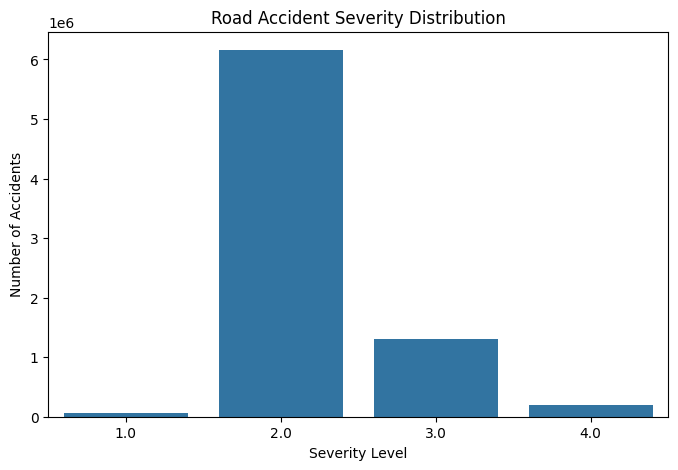

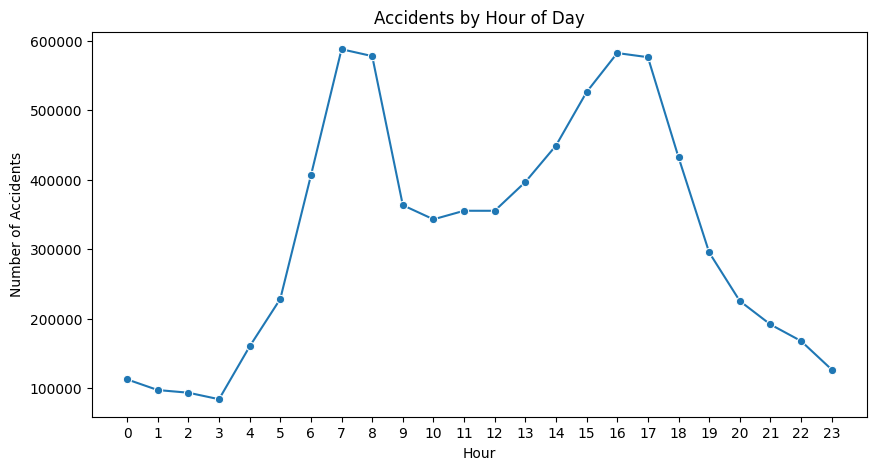

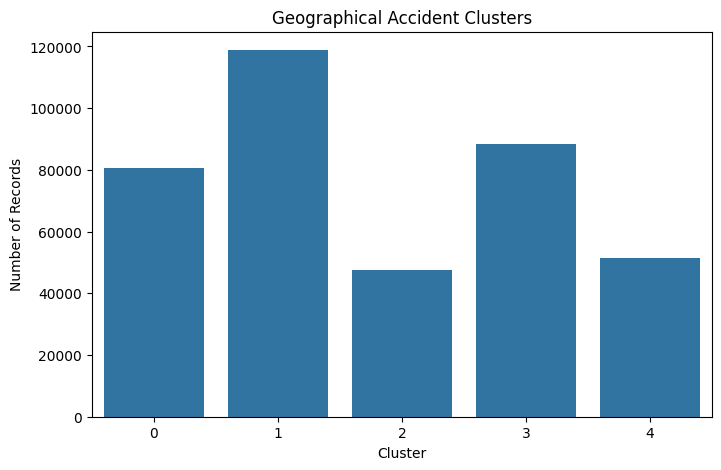

ALL VISUALIZATIONS CREATED SUCCESSFULLY!


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("/content/traffic_outputs", exist_ok=True)

# 1. Accident severity distribution
severity_data = (
    df_clean.groupBy("Severity")
    .count()
    .orderBy("Severity")
    .toPandas()
)

plt.figure(figsize=(8,5))
sns.barplot(data=severity_data, x="Severity", y="count")
plt.title("Road Accident Severity Distribution")
plt.xlabel("Severity Level")
plt.ylabel("Number of Accidents")
plt.savefig("/content/traffic_outputs/severity.png")
plt.show()


# 2. Accident by hour
hour_data = (
    df_clean.groupBy("Accident_Hour")
    .count()
    .orderBy("Accident_Hour")
    .toPandas()
)

plt.figure(figsize=(10,5))
sns.lineplot(data=hour_data, x="Accident_Hour", y="count", marker="o")
plt.title("Accidents by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Accidents")
plt.xticks(range(0,24))
plt.savefig("/content/traffic_outputs/hour_analysis.png")
plt.show()


# 3. K-Means cluster distribution
cluster_data = (
    cluster_results.groupBy("Cluster")
    .count()
    .orderBy("Cluster")
    .toPandas()
)

plt.figure(figsize=(8,5))
sns.barplot(data=cluster_data, x="Cluster", y="count")
plt.title("Geographical Accident Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.savefig("/content/traffic_outputs/clusters.png")
plt.show()

print("ALL VISUALIZATIONS CREATED SUCCESSFULLY!")

In [19]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(weighted_predictions)

f1 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
).evaluate(weighted_predictions)

print("SMART TRAFFIC ACCIDENT ANALYSIS")
print("--------------------------------")
print("Algorithm: Weighted Random Forest")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("F1 Score:", round(f1, 4))
print("--------------------------------")

SMART TRAFFIC ACCIDENT ANALYSIS
--------------------------------
Algorithm: Weighted Random Forest
Accuracy: 41.11 %
F1 Score: 0.4956
--------------------------------
